In [1]:
import sys
import radiomics

print("Python:", sys.version)
print("PyRadiomics:", radiomics.__version__)

Python: 3.11.18 (main, Oct 26 2026, 13:58:42) [Clang 23.1.3 ]
PyRadiomics: 3.1.1.dev111+g8ed579383


In [2]:
from pathlib import Path
import SimpleITK as sitk

# Define dataset location
project_directory = Path.cwd().parent
dataset_directory = project_directory / "Description and Sample of the DataSet-20261006"

# Select the first nodule
nodule_filename = "LIDC-IDRI-0001_R_1.nii.gz"

# Define image and mask paths
image_path = dataset_directory / "VOIs" / "image" / nodule_filename
mask_path = dataset_directory / "VOIs" / "nodule_mask" / nodule_filename

# Load image and mask
nodule_image = sitk.ReadImage(str(image_path))
nodule_mask = sitk.ReadImage(str(mask_path))

# Inspect image properties
print("Image size:", nodule_image.GetSize())
print("Mask size:", nodule_mask.GetSize())

print("Image spacing:", nodule_image.GetSpacing())
print("Mask spacing:", nodule_mask.GetSpacing())

Image size: (53, 64, 11)
Mask size: (53, 64, 11)
Image spacing: (0.703125, 0.703125, 2.5)
Mask spacing: (0.703125, 0.703125, 2.5)


In [3]:
from radiomics import featureextractor

# Initialize PyRadiomics feature extractor
extractor = featureextractor.RadiomicsFeatureExtractor()

# Extract features from the nodule image and mask
extracted_features = extractor.execute(
    str(image_path),
    str(mask_path)
)

# Display selected radiomic features
features_to_display = [
    "original_shape_VoxelVolume",
    "original_shape_SurfaceArea",
    "original_shape_Sphericity",
    "original_firstorder_Mean",
    "original_glcm_Contrast"
]

for feature_name in features_to_display:
    feature_value = extracted_features.get(feature_name)
    print(feature_name, ":", feature_value)

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


original_shape_VoxelVolume : 8091.8426513671875
original_shape_SurfaceArea : 2956.0448042649614
original_shape_Sphericity : 0.6552448557268963
original_firstorder_Mean : -161.66228807087217
original_glcm_Contrast : 80.44228438638376


In [4]:
# Identify the extracted radiomic features
radiomic_feature_names = []

for feature_name in extracted_features:

    if feature_name.startswith("original_"):
        radiomic_feature_names.append(feature_name)


# Display the number of extracted features
print("Total radiomic features:", len(radiomic_feature_names))

# Display the first 15 feature names
print("\nFirst 15 features:")

for feature_name in radiomic_feature_names[:15]:
    print(feature_name)

Total radiomic features: 107

First 15 features:
original_shape_Elongation
original_shape_Flatness
original_shape_LeastAxisLength
original_shape_MajorAxisLength
original_shape_Maximum2DDiameterColumn
original_shape_Maximum2DDiameterRow
original_shape_Maximum2DDiameterSlice
original_shape_Maximum3DDiameter
original_shape_MeshVolume
original_shape_MinorAxisLength
original_shape_Sphericity
original_shape_SurfaceArea
original_shape_SurfaceVolumeRatio
original_shape_VoxelVolume
original_firstorder_10Percentile


In [5]:
# Count features by category
feature_counts = {}

for feature_name in radiomic_feature_names:

    # Extract the feature category from its name
    feature_category = feature_name.split("_")[1]

    if feature_category not in feature_counts:
        feature_counts[feature_category] = 0

    feature_counts[feature_category] += 1


# Display results
for category, count in feature_counts.items():
    print(f"{category}: {count} features")

shape: 14 features
firstorder: 18 features
glcm: 24 features
gldm: 14 features
glrlm: 16 features
glszm: 16 features
ngtdm: 5 features


In [6]:
# Define image and mask directories
image_directory = dataset_directory / "VOIs" / "image"
mask_directory = dataset_directory / "VOIs" / "nodule_mask"

# Select the first 5 nodule images
image_files = sorted(image_directory.glob("*.nii.gz"))[:5]

# Test feature extraction
for image_file in image_files:

    mask_file = mask_directory / image_file.name

    try:
        features = extractor.execute(
            str(image_file),
            str(mask_file)
        )

        print(f"{image_file.name}: Extraction successful")

    except Exception as error:
        print(f"{image_file.name}: Extraction failed")
        print(error)

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


LIDC-IDRI-0001_R_1.nii.gz: Extraction successful
LIDC-IDRI-0003_R_2.nii.gz: Extraction successful
LIDC-IDRI-0003_R_3.nii.gz: Extraction successful


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


LIDC-IDRI-0003_R_4.nii.gz: Extraction successful


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


LIDC-IDRI-0004_R_1.nii.gz: Extraction successful


In [7]:
import pandas as pd

# Store the extracted features of each nodule
nodule_records = []

for image_file in image_files:

    mask_file = mask_directory / image_file.name

    # Extract radiomic features
    features = extractor.execute(
        str(image_file),
        str(mask_file)
    )

    # Extract patient and nodule identifiers
    filename = image_file.name.removesuffix(".nii.gz")
    patient_id, nodule_id = filename.split("_R_")

    # Create a record for this nodule
    nodule_record = {
        "patient_id": patient_id,
        "nodule_id": int(nodule_id)
    }

    # Add the radiomic features to the record
    for feature_name in radiomic_feature_names:
        nodule_record[feature_name] = float(features[feature_name])

    nodule_records.append(nodule_record)


# Convert the records into a DataFrame
radiomics_dataset = pd.DataFrame(nodule_records)

print("Dataset dimensions:", radiomics_dataset.shape)

display(radiomics_dataset.iloc[:, :7])

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


Dataset dimensions: (5, 109)


,patient_id,nodule_id,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn
0,LIDC-IDRI-0001,1,0.969487,0.860174,21.003480,24.417710,30.103986
1,LIDC-IDRI-0003,2,0.888136,0.581619,18.039371,31.015808,35.666423
2,LIDC-IDRI-0003,3,0.673941,0.649285,7.949830,12.243980,13.469311
3,LIDC-IDRI-0003,4,0.835362,0.804038,11.747163,14.610216,20.267377
4,LIDC-IDRI-0004,1,0.851577,0.779727,5.314192,6.815455,7.811263


In [8]:
# Find all available nodule images
all_image_files = sorted(image_directory.glob("*.nii.gz"))

# Prepare lists for results and errors
nodule_records = []
failed_extractions = []

print("Images to process:", len(all_image_files))

# Extract features from each nodule
for image_number, image_file in enumerate(all_image_files, start=1):

    mask_file = mask_directory / image_file.name

    if not mask_file.exists():
        failed_extractions.append((image_file.name, "Missing mask"))
        continue

    try:
        # Extract radiomic features
        extracted_features = extractor.execute(
            str(image_file),
            str(mask_file)
        )

        # Identify the patient and nodule
        filename = image_file.name.removesuffix(".nii.gz")
        patient_id, nodule_id = filename.split("_R_")

        nodule_record = {
            "patient_id": patient_id,
            "nodule_id": int(nodule_id)
        }

        # Add the extracted features
        for feature_name in radiomic_feature_names:
            feature_value = extracted_features[feature_name]
            nodule_record[feature_name] = float(feature_value)

        nodule_records.append(nodule_record)

    except Exception as error:
        failed_extractions.append((image_file.name, str(error)))

    # Display progress every 25 images
    if image_number % 25 == 0:
        print(f"Processed {image_number} of {len(all_image_files)} images")


# Create the complete dataset
radiomics_dataset = pd.DataFrame(nodule_records)

# Save the extracted features
output_path = project_directory / "results" / "radiomics_features.csv"

radiomics_dataset.to_csv(output_path, index=False)

# Display extraction summary
print("\nExtraction completed")
print("Successful extractions:", len(nodule_records))
print("Failed extractions:", len(failed_extractions))
print("Dataset dimensions:", radiomics_dataset.shape)
print("Saved to:", output_path)

display(radiomics_dataset.head())

Images to process: 994


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

Processed 25 of 994 images


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

Processed 50 of 994 images


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

... (72 outputs left out)

Processed 975 of 994 images


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated



Extraction completed
Successful extractions: 994
Failed extractions: 0
Dataset dimensions: (994, 109)
Saved to: /Users/omargutierrez/Luna Dataset Project/results/radiomics_features.csv


,patient_id,nodule_id,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,LIDC-IDRI-0001,1,0.969487,0.860174,21.003480,24.417710,30.103986,33.842466,34.738929,36.390152,...,457.133374,0.004362,6.712857,0.407668,356.247040,0.506478,0.001145,3691.077373,0.494586,1.211626
1,LIDC-IDRI-0003,2,0.888136,0.581619,18.039371,31.015808,35.666423,35.035215,33.991022,39.760410,...,323.295565,0.005548,6.889498,0.370646,140.357697,0.709235,0.001520,3044.802147,0.443948,1.437845
2,LIDC-IDRI-0003,3,0.673941,0.649285,7.949830,12.243980,13.469311,11.145619,13.227134,14.151461,...,228.034156,0.018957,5.873319,0.654545,2.017747,0.208307,0.010943,3930.638483,1.237060,6.090407
3,LIDC-IDRI-0003,4,0.835362,0.804038,11.747163,14.610216,20.267377,20.267377,14.788385,20.333672,...,395.403776,0.009473,6.071002,0.525952,55.417893,0.185347,0.004468,4320.436125,1.157649,4.261567
4,LIDC-IDRI-0004,1,0.851577,0.779727,5.314192,6.815455,7.811263,7.962592,7.800700,8.194283,...,579.565211,0.023466,5.902933,0.706250,1.074791,0.059115,0.025284,9932.526324,1.377353,52.136354


In [9]:
import numpy as np

# Select only the radiomic features
feature_data = radiomics_dataset.drop(
    columns=["patient_id", "nodule_id"]
)

# Check for missing values
missing_values = feature_data.isna().sum().sum()

# Check for infinite values
infinite_values = np.isinf(feature_data.to_numpy()).sum()

# Check for duplicated nodules
duplicated_nodules = radiomics_dataset.duplicated(
    subset=["patient_id", "nodule_id"]
).sum()

print("Missing values:", missing_values)
print("Infinite values:", infinite_values)
print("Duplicated nodules:", duplicated_nodules)

Missing values: 0
Infinite values: 0
Duplicated nodules: 0


In [10]:
# Load the original metadata
metadata_path = dataset_directory / "MetadatabyAnnotation.xlsx"
metadata = pd.read_excel(metadata_path)

# Identify suspicious malignancy assessments
metadata["suspicious_assessment"] = (
    metadata["Malignancy_value"] > 3
)

# Group annotations belonging to the same nodule
nodule_identifiers = ["patient_id", "nodule_id"]

nodule_assessments = metadata.groupby(
    nodule_identifiers,
    as_index=False
).agg(
    suspicious_count=("suspicious_assessment", "sum"),
    annotation_count=("Malignancy_value", "size")
)

# Apply the classification rule defined in LUNA16
nodule_assessments["malignancy_label"] = (
    nodule_assessments["suspicious_count"] >= 2
).astype(int)

# Inspect the results
print("Total classified nodules:", len(nodule_assessments))

print("\nMalignancy distribution:")
print(nodule_assessments["malignancy_label"].value_counts())

print("\nNodules with more than 4 annotation records:")
print((nodule_assessments["annotation_count"] > 4).sum())

display(nodule_assessments.head())

Total classified nodules: 996

Malignancy distribution:
malignancy_label
0    650
1    346
Name: count, dtype: int64

Nodules with more than 4 annotation records:
6


,patient_id,nodule_id,suspicious_count,annotation_count,malignancy_label
0,LIDC-IDRI-0001,1,4,4,1
1,LIDC-IDRI-0003,2,3,4,1
2,LIDC-IDRI-0003,3,2,4,1
3,LIDC-IDRI-0003,4,2,4,1
4,LIDC-IDRI-0004,1,0,4,0


In [11]:
# Select the information needed for classification
malignancy_data = nodule_assessments[
    ["patient_id", "nodule_id", "malignancy_label"]
]

# Combine radiomic features with malignancy labels
classification_dataset = radiomics_dataset.merge(
    malignancy_data,
    on=["patient_id", "nodule_id"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check whether all nodules found their metadata
unmatched_nodules = classification_dataset[
    classification_dataset["_merge"] != "both"
]

print("Total nodules:", len(classification_dataset))
print("Nodules without malignancy label:", len(unmatched_nodules))

# Remove the temporary merge indicator
classification_dataset = classification_dataset.drop(
    columns=["_merge"]
)

# Display the class distribution
print("\nMalignancy distribution:")
print(classification_dataset["malignancy_label"].value_counts())

print("\nDataset dimensions:", classification_dataset.shape)

display(classification_dataset.head())

Total nodules: 994
Nodules without malignancy label: 0

Malignancy distribution:
malignancy_label
0    650
1    344
Name: count, dtype: int64

Dataset dimensions: (994, 110)


,patient_id,nodule_id,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,malignancy_label
0,LIDC-IDRI-0001,1,0.969487,0.860174,21.003480,24.417710,30.103986,33.842466,34.738929,36.390152,...,0.004362,6.712857,0.407668,356.247040,0.506478,0.001145,3691.077373,0.494586,1.211626,1
1,LIDC-IDRI-0003,2,0.888136,0.581619,18.039371,31.015808,35.666423,35.035215,33.991022,39.760410,...,0.005548,6.889498,0.370646,140.357697,0.709235,0.001520,3044.802147,0.443948,1.437845,1
2,LIDC-IDRI-0003,3,0.673941,0.649285,7.949830,12.243980,13.469311,11.145619,13.227134,14.151461,...,0.018957,5.873319,0.654545,2.017747,0.208307,0.010943,3930.638483,1.237060,6.090407,1
3,LIDC-IDRI-0003,4,0.835362,0.804038,11.747163,14.610216,20.267377,20.267377,14.788385,20.333672,...,0.009473,6.071002,0.525952,55.417893,0.185347,0.004468,4320.436125,1.157649,4.261567,1
4,LIDC-IDRI-0004,1,0.851577,0.779727,5.314192,6.815455,7.811263,7.962592,7.800700,8.194283,...,0.023466,5.902933,0.706250,1.074791,0.059115,0.025284,9932.526324,1.377353,52.136354,0


In [12]:
# Identify nodules with more than four annotation records
unusual_nodules = nodule_assessments[
    nodule_assessments["annotation_count"] > 4
]

# Find their original annotations
unusual_annotations = metadata.merge(
    unusual_nodules[["patient_id", "nodule_id"]],
    on=["patient_id", "nodule_id"],
    how="inner"
)

# Display relevant information
columns_to_display = [
    "patient_id",
    "nodule_id",
    "seriesuid",
    "anotation_id",
    "Malignancy_value",
    "diameter_mm"
]

display(
    unusual_annotations[columns_to_display].sort_values(
        ["patient_id", "nodule_id", "anotation_id"]
    )
)

,patient_id,nodule_id,seriesuid,anotation_id,Malignancy_value,diameter_mm
0,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1717,4,15.992350
1,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1718,3,15.992350
2,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1719,5,15.992350
3,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1720,5,15.992350
4,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1721,4,15.992350
5,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1722,4,15.992350
6,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1981,5,16.828939
7,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1982,3,16.828939
8,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1983,5,16.828939
9,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1984,4,16.828939


In [13]:
# Select nodules with more than four annotations
unusual_nodules = nodule_assessments[
    nodule_assessments["annotation_count"] > 4
]

# Retrieve their original metadata records
unusual_annotations = metadata.merge(
    unusual_nodules[["patient_id", "nodule_id"]],
    on=["patient_id", "nodule_id"],
    how="inner"
)

# Select relevant columns for inspection
columns_to_review = [
    "patient_id",
    "nodule_id",
    "seriesuid",
    "anotation_id",
    "Malignancy_value",
    "diameter_mm"
]

# Display the annotations ordered by nodule
display(
    unusual_annotations[columns_to_review].sort_values(
        by=["patient_id", "nodule_id", "anotation_id"]
    )
)

,patient_id,nodule_id,seriesuid,anotation_id,Malignancy_value,diameter_mm
0,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1717,4,15.992350
1,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1718,3,15.992350
2,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1719,5,15.992350
3,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1720,5,15.992350
4,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1721,4,15.992350
5,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1722,4,15.992350
6,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1981,5,16.828939
7,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1982,3,16.828939
8,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1983,5,16.828939
9,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1984,4,16.828939


In [14]:
# Count different CT series associated with each nodule
series_per_nodule = metadata.groupby(
    ["patient_id", "nodule_id"]
)["seriesuid"].nunique()

# Identify nodules associated with multiple CT series
nodules_with_multiple_series = series_per_nodule[
    series_per_nodule > 1
]

print("Nodules with multiple CT series:")
display(nodules_with_multiple_series)

Nodules with multiple CT series:


patient_id      nodule_id
LIDC-IDRI-0332  1            2
Name: seriesuid, dtype: int64

In [15]:
# Identify the nodule with ambiguous CT series
ambiguous_nodule = (
    (classification_dataset["patient_id"] == "LIDC-IDRI-0332") &
    (classification_dataset["nodule_id"] == 1)
)

# Exclude the ambiguous nodule
clean_classification_dataset = classification_dataset[
    ~ambiguous_nodule
].copy()

# Save the cleaned dataset
output_path = project_directory / "results" / "classification_dataset.csv"

clean_classification_dataset.to_csv(output_path, index=False)

# Display results
print("Original nodules:", len(classification_dataset))
print("Excluded nodules:", ambiguous_nodule.sum())
print("Final nodules:", len(clean_classification_dataset))

print("\nClass distribution:")
print(clean_classification_dataset["malignancy_label"].value_counts())

Original nodules: 994
Excluded nodules: 1
Final nodules: 993

Class distribution:
malignancy_label
0    650
1    343
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import StratifiedGroupKFold

# Separate radiomic features, labels and patient identifiers
feature_columns = [
    column for column in clean_classification_dataset.columns
    if column.startswith("original_")
]

features = clean_classification_dataset[feature_columns]
labels = clean_classification_dataset["malignancy_label"]
patients = clean_classification_dataset["patient_id"]

# Create a patient-based split
data_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Reserve one fold for testing
splits = data_splitter.split(features, labels, groups=patients)

training_indices, testing_indices = next(splits)

# Create training and testing datasets
training_dataset = clean_classification_dataset.iloc[
    training_indices
].copy()

testing_dataset = clean_classification_dataset.iloc[
    testing_indices
].copy()

# Verify the split
training_patients = set(training_dataset["patient_id"])
testing_patients = set(testing_dataset["patient_id"])

shared_patients = training_patients.intersection(testing_patients)

print("Training nodules:", len(training_dataset))
print("Testing nodules:", len(testing_dataset))
print("Shared patients:", len(shared_patients))

print("\nTraining class distribution:")
print(training_dataset["malignancy_label"].value_counts())

print("\nTesting class distribution:")
print(testing_dataset["malignancy_label"].value_counts())

Training nodules: 793
Testing nodules: 200
Shared patients: 0

Training class distribution:
malignancy_label
0    519
1    274
Name: count, dtype: int64

Testing class distribution:
malignancy_label
0    131
1     69
Name: count, dtype: int64


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Prepare training data
training_features = training_dataset[feature_columns]
training_labels = training_dataset["malignancy_label"]
training_patients = training_dataset["patient_id"]

# Create our first Random Forest classifier
random_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Configure patient-based cross-validation
cross_validation = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the classifier
validation_results = cross_validate(
    random_forest,
    training_features,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)

# Display average performance
for metric in ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]:
    scores = validation_results["test_" + metric]

    print(f"{metric}: {scores.mean():.3f} (+/- {scores.std():.3f})")

accuracy: 0.865 (+/- 0.037)
balanced_accuracy: 0.857 (+/- 0.037)
precision: 0.794 (+/- 0.063)
recall: 0.832 (+/- 0.056)
f1: 0.811 (+/- 0.047)


Testing results:

              precision    recall  f1-score   support

      Benign       0.92      0.95      0.93       131
  Suspicious       0.89      0.84      0.87        69

    accuracy                           0.91       200
   macro avg       0.91      0.89      0.90       200
weighted avg       0.91      0.91      0.91       200



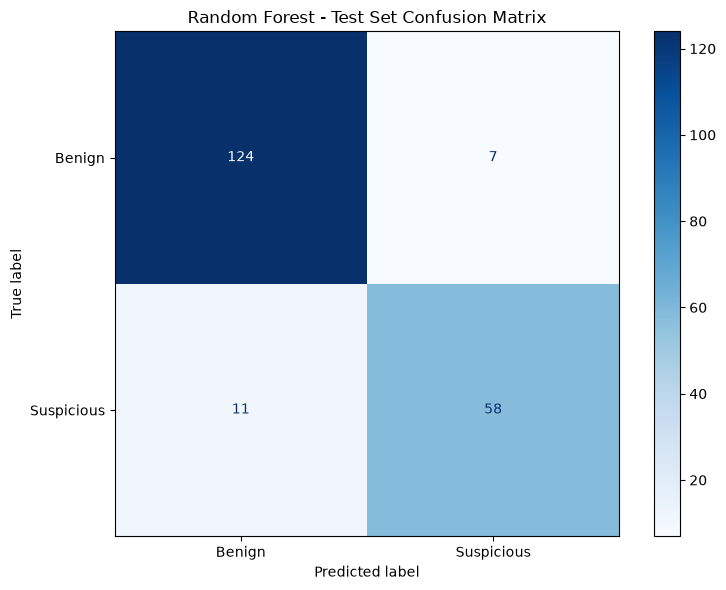

In [20]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train the model using all training nodules
random_forest.fit(training_features, training_labels)

# Prepare the testing dataset
testing_features = testing_dataset[feature_columns]
testing_labels = testing_dataset["malignancy_label"]

# Predict malignancy for the testing nodules
predicted_labels = random_forest.predict(testing_features)

# Display classification performance
print("Testing results:\n")

print(
    classification_report(
        testing_labels,
        predicted_labels,
        target_names=["Benign", "Suspicious"]
    )
)

# Create confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    testing_labels,
    predicted_labels,
    display_labels=["Benign", "Suspicious"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Random Forest - Test Set Confusion Matrix")

plt.tight_layout()

# Save figure before displaying it
fig.savefig(
    project_directory / "results" / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Feature,Importance
9,original_shape_MinorAxisLength,0.070991
13,original_shape_VoxelVolume,0.061685
103,original_ngtdm_Coarseness,0.059643
8,original_shape_MeshVolume,0.059144
6,original_shape_Maximum2DDiameterSlice,0.047822
11,original_shape_SurfaceArea,0.046779
2,original_shape_LeastAxisLength,0.035956
12,original_shape_SurfaceVolumeRatio,0.029316
86,original_glszm_GrayLevelNonUniformity,0.027651
70,original_glrlm_GrayLevelNonUniformity,0.026067


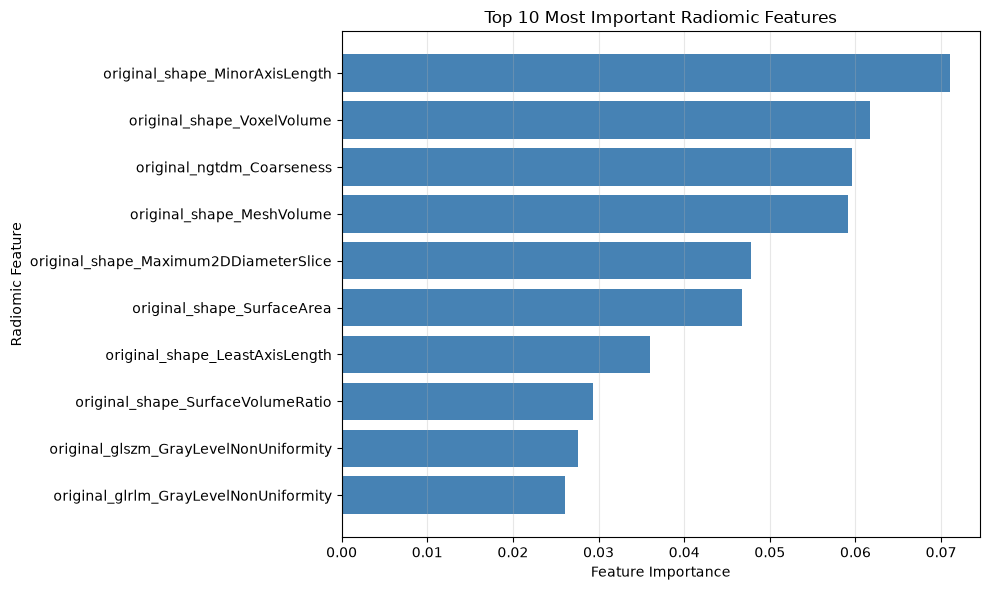

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance values from the trained Random Forest
feature_importance_values = random_forest.feature_importances_

# Create a table with feature names and importance values
feature_importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": feature_importance_values
})

# Sort features from highest to lowest importance
feature_importance_table = feature_importance_table.sort_values(
    by="Importance",
    ascending=False
)

# Select the 10 most important features
top_10_features = feature_importance_table.head(10)

display(top_10_features)


# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_10_features["Feature"],
    top_10_features["Importance"],
    color="steelblue"
)

ax.invert_yaxis()

ax.set_title("Top 10 Most Important Radiomic Features")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Radiomic Feature")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save the figure
fig.savefig(
    project_directory / "results" / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# Select only shape features
shape_feature_columns = []

for feature_name in feature_columns:
    if feature_name.startswith("original_shape_"):
        shape_feature_columns.append(feature_name)

shape_training_features = training_dataset[shape_feature_columns]

# Create a Random Forest using only shape features
shape_random_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Evaluate the reduced model using cross-validation
shape_validation_results = cross_validate(
    shape_random_forest,
    shape_training_features,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)

# Compare both models
print("Original model: 107 features")
print("Reduced model:", len(shape_feature_columns), "features\n")

for metric_name in ["accuracy", "balanced_accuracy", "recall", "f1"]:

    original_scores = validation_results["test_" + metric_name]
    reduced_scores = shape_validation_results["test_" + metric_name]

    print(metric_name)
    print("  Original:", round(original_scores.mean(), 3))
    print("  Reduced: ", round(reduced_scores.mean(), 3))

Original model: 107 features
Reduced model: 14 features

accuracy
  Original: 0.865
  Reduced:  0.856
balanced_accuracy
  Original: 0.857
  Reduced:  0.849
recall
  Original: 0.832
  Reduced:  0.828
f1
  Original: 0.811
  Reduced:  0.799


In [23]:
# Select intensity and texture features
texture_intensity_columns = []

for feature_name in feature_columns:

    if not feature_name.startswith("original_shape_"):
        texture_intensity_columns.append(feature_name)


# Prepare training data
texture_intensity_training = training_dataset[
    texture_intensity_columns
]


# Create a Random Forest without shape features
texture_intensity_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


# Evaluate using the same patient-based cross-validation
texture_intensity_results = cross_validate(
    texture_intensity_forest,
    texture_intensity_training,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)


# Compare the three models
models = {
    "All features (107)": validation_results,
    "Shape only (14)": shape_validation_results,
    "Intensity + Texture (93)": texture_intensity_results
}

comparison_results = []

for model_name, model_results in models.items():

    model_statistics = {"Model": model_name}

    for metric_name in ["accuracy", "balanced_accuracy", "recall", "f1"]:

        scores = model_results["test_" + metric_name]
        model_statistics[metric_name] = scores.mean()

    comparison_results.append(model_statistics)


comparison_table = pd.DataFrame(comparison_results)

display(comparison_table.round(3))

,Model,accuracy,balanced_accuracy,recall,f1
0,All features (107),0.865,0.857,0.832,0.811
1,Shape only (14),0.856,0.849,0.828,0.799
2,Intensity + Texture (93),0.866,0.857,0.829,0.811


In [24]:
# Separate intensity and texture features
intensity_columns = []
texture_columns = []

for feature_name in feature_columns:

    if feature_name.startswith("original_firstorder_"):
        intensity_columns.append(feature_name)

    elif not feature_name.startswith("original_shape_"):
        texture_columns.append(feature_name)


print("Intensity features:", len(intensity_columns))
print("Texture features:", len(texture_columns))


# Evaluate the model using only intensity features
intensity_results = cross_validate(
    random_forest,
    training_dataset[intensity_columns],
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "recall", "f1"]
)


# Evaluate the model using only texture features
texture_results = cross_validate(
    random_forest,
    training_dataset[texture_columns],
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "recall", "f1"]
)


# Compare all five feature groups
models = {
    "All features (107)": validation_results,
    "Shape only (14)": shape_validation_results,
    "Intensity + Texture (93)": texture_intensity_results,
    "Intensity only (18)": intensity_results,
    "Texture only (75)": texture_results
}

comparison_results = []

for model_name, model_results in models.items():

    model_statistics = {"Model": model_name}

    for metric_name in ["accuracy", "balanced_accuracy", "recall", "f1"]:

        scores = model_results["test_" + metric_name]
        model_statistics[metric_name] = scores.mean()

    comparison_results.append(model_statistics)


comparison_table = pd.DataFrame(comparison_results)

display(comparison_table.round(3))

Intensity features: 18
Texture features: 75


,Model,accuracy,balanced_accuracy,recall,f1
0,All features (107),0.865,0.857,0.832,0.811
1,Shape only (14),0.856,0.849,0.828,0.799
2,Intensity + Texture (93),0.866,0.857,0.829,0.811
3,Intensity only (18),0.855,0.847,0.821,0.796
4,Texture only (75),0.859,0.852,0.829,0.802


In [25]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Create the SVM classifier
svm_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced"
    ))
])

# Evaluate using the same patient-based cross-validation
svm_validation_results = cross_validate(
    svm_classifier,
    training_features,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)

# Compare Random Forest and SVM
models_to_compare = {
    "Random Forest": validation_results,
    "SVM": svm_validation_results
}

comparison_results = []

for model_name, model_results in models_to_compare.items():

    model_statistics = {"Model": model_name}

    for metric_name in ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]:

        metric_scores = model_results["test_" + metric_name]

        model_statistics[metric_name] = metric_scores.mean()

    comparison_results.append(model_statistics)

# Display comparison
svm_comparison_table = pd.DataFrame(comparison_results)

display(svm_comparison_table.round(3))

,Model,accuracy,balanced_accuracy,precision,recall,f1
0,Random Forest,0.865,0.857,0.794,0.832,0.811
1,SVM,0.861,0.865,0.765,0.876,0.814


SVM Testing Results:

              precision    recall  f1-score   support

      Benign       0.91      0.92      0.91       131
  Suspicious       0.84      0.83      0.83        69

    accuracy                           0.89       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.88      0.89      0.88       200



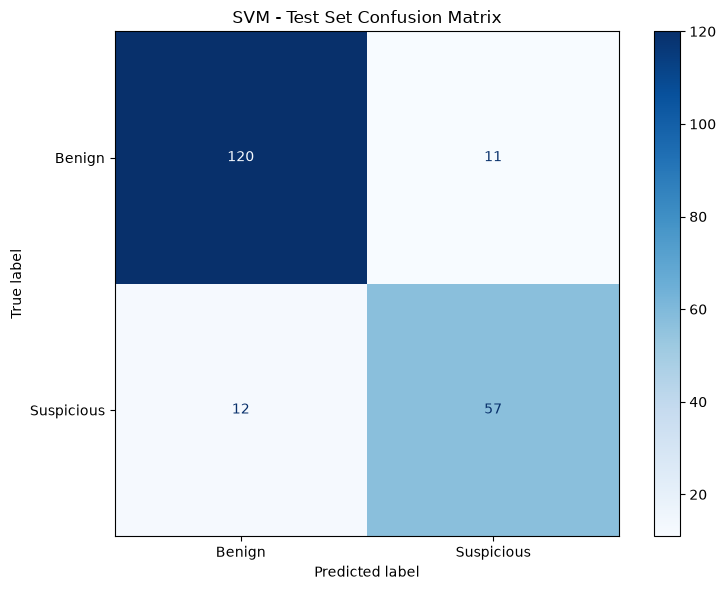

In [27]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train SVM using the complete training set
svm_classifier.fit(training_features, training_labels)

# Prepare the testing data
svm_testing_features = testing_dataset[feature_columns]
svm_testing_labels = testing_dataset["malignancy_label"]

# Predict malignancy using SVM
svm_predictions = svm_classifier.predict(svm_testing_features)

# Display classification metrics
print("SVM Testing Results:\n")

print(
    classification_report(
        svm_testing_labels,
        svm_predictions,
        target_names=["Benign", "Suspicious"]
    )
)

# Create confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    svm_testing_labels,
    svm_predictions,
    display_labels=["Benign", "Suspicious"],
    cmap="Blues",
    ax=ax
)

ax.set_title("SVM - Test Set Confusion Matrix")

plt.tight_layout()

# Save figure in results before displaying
fig.savefig(
    project_directory / "results" / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to evaluate
svm_parameters = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1]
}

# Configure the hyperparameter search
svm_grid_search = GridSearchCV(
    estimator=svm_classifier,
    param_grid=svm_parameters,
    scoring="f1",
    cv=cross_validation,
    n_jobs=-1,
    refit=True
)

# Find the best parameters using only training data
svm_grid_search.fit(
    training_features,
    training_labels,
    groups=training_patients
)

# Display the best configuration
print("Best SVM parameters:")
print(svm_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(svm_grid_search.best_score_, 3))

Best SVM parameters:
{'svm__C': 100, 'svm__gamma': 0.001}

Best cross-validation F1-score:
0.821


In [29]:
# Store the results of all parameter combinations
svm_tuning_results = pd.DataFrame(
    svm_grid_search.cv_results_
)

# Select the relevant columns
svm_tuning_summary = svm_tuning_results[
    [
        "param_svm__C",
        "param_svm__gamma",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

# Sort configurations by F1-score
svm_tuning_summary = svm_tuning_summary.sort_values(
    by="mean_test_score",
    ascending=False
)

# Display the results
display(svm_tuning_summary.round(3))

# Save results for the report
svm_tuning_summary.to_csv(
    project_directory / "results" / "svm_hyperparameter_tuning.csv",
    index=False
)

,param_svm__C,param_svm__gamma,mean_test_score,std_test_score
13,100.0,0.001,0.821,0.038
5,1.0,0.001,0.819,0.045
9,10.0,0.001,0.819,0.032
0,0.1,scale,0.814,0.036
4,1.0,scale,0.814,0.035
6,1.0,0.01,0.814,0.035
2,0.1,0.01,0.810,0.032
10,10.0,0.01,0.784,0.047
8,10.0,scale,0.784,0.041
1,0.1,0.001,0.777,0.037


In [30]:
from sklearn.base import clone
from sklearn.metrics import f1_score, recall_score, balanced_accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

# Configure the inner cross-validation
inner_cross_validation = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Store the evaluation results
nested_validation_results = []

# Evaluate the optimized SVM using outer cross-validation
for fold_number, (train_indices, validation_indices) in enumerate(
    cross_validation.split(
        training_features,
        training_labels,
        groups=training_patients
    ),
    start=1
):

    # Separate training and validation data for this fold
    fold_training_features = training_features.iloc[train_indices]
    fold_training_labels = training_labels.iloc[train_indices]
    fold_training_patients = training_patients.iloc[train_indices]

    fold_validation_features = training_features.iloc[validation_indices]
    fold_validation_labels = training_labels.iloc[validation_indices]

    # Search for the best SVM parameters
    parameter_search = GridSearchCV(
        estimator=clone(svm_classifier),
        param_grid=svm_parameters,
        scoring="f1",
        cv=inner_cross_validation,
        n_jobs=-1
    )

    parameter_search.fit(
        fold_training_features,
        fold_training_labels,
        groups=fold_training_patients
    )

    # Evaluate the selected model on the outer validation fold
    predictions = parameter_search.predict(fold_validation_features)

    fold_result = {
        "Fold": fold_number,
        "F1": f1_score(fold_validation_labels, predictions),
        "Recall": recall_score(fold_validation_labels, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            fold_validation_labels,
            predictions
        ),
        "Best C": parameter_search.best_params_["svm__C"],
        "Best Gamma": parameter_search.best_params_["svm__gamma"]
    }

    nested_validation_results.append(fold_result)

    print(f"Fold {fold_number} completed")


# Display and save results
nested_results_table = pd.DataFrame(nested_validation_results)

display(nested_results_table.round(3))

nested_results_table.to_csv(
    project_directory / "results" / "svm_nested_validation.csv",
    index=False
)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


,Fold,F1,Recall,Balanced Accuracy,Best C,Best Gamma
0,1,0.862,0.909,0.902,1,scale
1,2,0.788,0.945,0.851,1,0.01
2,3,0.839,0.870,0.883,1,0.01
3,4,0.779,0.800,0.832,10,0.001
4,5,0.817,0.891,0.868,1,0.01


In [31]:
# Compare the average validation results
print("Random Forest F1:", round(validation_results["test_f1"].mean(), 3))

print("Original SVM F1:", round(svm_validation_results["test_f1"].mean(), 3))

print("Optimized SVM F1:", round(nested_results_table["F1"].mean(), 3))

print("\nOptimized SVM Recall:", round(nested_results_table["Recall"].mean(), 3))

print(
    "Optimized SVM Balanced Accuracy:",
    round(nested_results_table["Balanced Accuracy"].mean(), 3)
)


Random Forest F1: 0.811
Original SVM F1: 0.814
Optimized SVM F1: 0.817

Optimized SVM Recall: 0.883
Optimized SVM Balanced Accuracy: 0.867


In [32]:
# Create a table with the testing nodules
error_analysis = testing_dataset[
    ["patient_id", "nodule_id", "malignancy_label"]
].copy()

# Add predictions from both classifiers
error_analysis["rf_prediction"] = predicted_labels
error_analysis["svm_prediction"] = svm_predictions

# Identify classification errors
error_analysis["rf_error"] = (
    error_analysis["rf_prediction"] != error_analysis["malignancy_label"]
)

error_analysis["svm_error"] = (
    error_analysis["svm_prediction"] != error_analysis["malignancy_label"]
)

# Identify nodules misclassified by both models
error_analysis["both_models_wrong"] = (
    error_analysis["rf_error"] & error_analysis["svm_error"]
)

# Count errors
print("Random Forest errors:", error_analysis["rf_error"].sum())
print("SVM errors:", error_analysis["svm_error"].sum())

print(
    "Nodules misclassified by both models:",
    error_analysis["both_models_wrong"].sum()
)

# Display nodules where both models failed
display(
    error_analysis[
        error_analysis["both_models_wrong"]
    ]
)

# Save results
error_analysis.to_csv(
    project_directory / "results" / "classification_error_analysis.csv",
    index=False
)

Random Forest errors: 18
SVM errors: 23
Nodules misclassified by both models: 18


,patient_id,nodule_id,malignancy_label,rf_prediction,svm_prediction,rf_error,svm_error,both_models_wrong
194,LIDC-IDRI-0140,1,0,1,1,True,True,True
227,LIDC-IDRI-0164,2,1,0,0,True,True,True
390,LIDC-IDRI-0312,2,1,0,0,True,True,True
391,LIDC-IDRI-0312,3,1,0,0,True,True,True
399,LIDC-IDRI-0326,1,1,0,0,True,True,True
461,LIDC-IDRI-0409,2,0,1,1,True,True,True
508,LIDC-IDRI-0454,4,1,0,0,True,True,True
524,LIDC-IDRI-0469,1,1,0,0,True,True,True
540,LIDC-IDRI-0481,7,1,0,0,True,True,True
579,LIDC-IDRI-0523,2,0,1,1,True,True,True


In [33]:
# Identify nodules misclassified only by SVM
svm_only_errors = error_analysis[
    (error_analysis["svm_error"]) &
    (~error_analysis["rf_error"])
]

print("Errors exclusive to SVM:", len(svm_only_errors))

display(svm_only_errors)

Errors exclusive to SVM: 5


,patient_id,nodule_id,malignancy_label,rf_prediction,svm_prediction,rf_error,svm_error,both_models_wrong
2,LIDC-IDRI-0003,3,1,1,0,False,True,False
420,LIDC-IDRI-0356,5,0,0,1,False,True,False
446,LIDC-IDRI-0402,4,0,0,1,False,True,False
539,LIDC-IDRI-0481,6,0,0,1,False,True,False
740,LIDC-IDRI-0705,2,0,0,1,False,True,False


Correctly classified by both: 177
Misclassified by both: 18

Median volume of correctly classified nodules:
188.65722156479023

Median volume of incorrectly classified nodules:
338.05274963378906


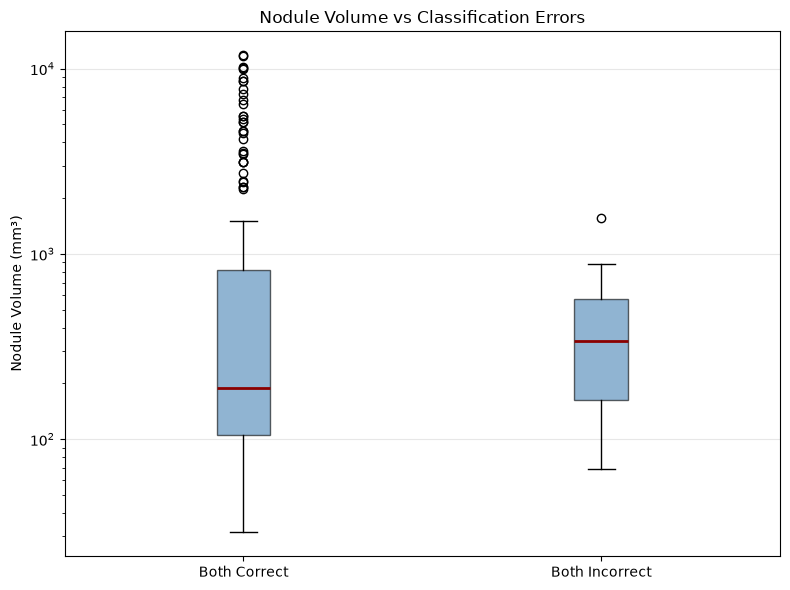

In [34]:
# Add nodule volume to the error analysis
error_analysis["volume_mm3"] = testing_dataset[
    "original_shape_VoxelVolume"
]

# Identify nodules correctly classified by both models
both_models_correct = (
    (~error_analysis["rf_error"]) &
    (~error_analysis["svm_error"])
)

# Select correctly classified nodules
correct_nodules = error_analysis[both_models_correct]

# Select nodules misclassified by both models
incorrect_nodules = error_analysis[
    error_analysis["both_models_wrong"]
]

# Compare volume statistics
print("Correctly classified by both:", len(correct_nodules))
print("Misclassified by both:", len(incorrect_nodules))

print("\nMedian volume of correctly classified nodules:")
print(correct_nodules["volume_mm3"].median())

print("\nMedian volume of incorrectly classified nodules:")
print(incorrect_nodules["volume_mm3"].median())


# Prepare data for visualization
volume_groups = [
    correct_nodules["volume_mm3"],
    incorrect_nodules["volume_mm3"]
]

# Create boxplot
fig, ax = plt.subplots(figsize=(8, 6))

ax.boxplot(
    volume_groups,
    tick_labels=["Both Correct", "Both Incorrect"],
    patch_artist=True,
    boxprops={"facecolor": "steelblue", "alpha": 0.6},
    medianprops={"color": "darkred", "linewidth": 2}
)

ax.set_title("Nodule Volume vs Classification Errors")
ax.set_ylabel("Nodule Volume (mm³)")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save the figure
fig.savefig(
    project_directory / "results" / "volume_vs_classification_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
# Compare nodule volumes within each malignancy class
for malignancy_label in [0, 1]:

    correct_group = correct_nodules[
        correct_nodules["malignancy_label"] == malignancy_label
    ]

    incorrect_group = incorrect_nodules[
        incorrect_nodules["malignancy_label"] == malignancy_label
    ]

    print(f"\nMalignancy label: {malignancy_label}")

    print("Correctly classified:", len(correct_group))
    print("Incorrectly classified:", len(incorrect_group))

    print("Median volume (correct):",
          round(correct_group["volume_mm3"].median(), 2))

    print("Median volume (incorrect):",
          round(incorrect_group["volume_mm3"].median(), 2))


Malignancy label: 0
Correctly classified: 120
Incorrectly classified: 7
Median volume (correct): 137.88
Median volume (incorrect): 564.19

Malignancy label: 1
Correctly classified: 57
Incorrectly classified: 11
Median volume (correct): 2476.5
Median volume (incorrect): 172.67


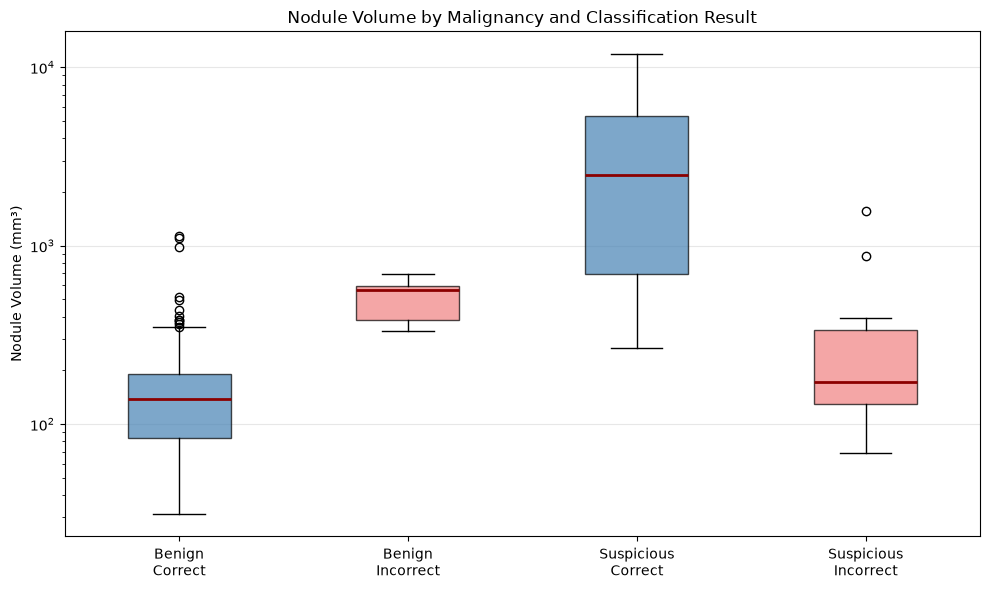

In [36]:
# Separate nodules by malignancy and classification result
benign_correct = correct_nodules[
    correct_nodules["malignancy_label"] == 0
]

benign_incorrect = incorrect_nodules[
    incorrect_nodules["malignancy_label"] == 0
]

suspicious_correct = correct_nodules[
    correct_nodules["malignancy_label"] == 1
]

suspicious_incorrect = incorrect_nodules[
    incorrect_nodules["malignancy_label"] == 1
]


# Prepare volume data for the boxplot
volume_groups = [
    benign_correct["volume_mm3"],
    benign_incorrect["volume_mm3"],
    suspicious_correct["volume_mm3"],
    suspicious_incorrect["volume_mm3"]
]

group_labels = [
    "Benign\nCorrect",
    "Benign\nIncorrect",
    "Suspicious\nCorrect",
    "Suspicious\nIncorrect"
]


# Create boxplot
fig, ax = plt.subplots(figsize=(10, 6))

boxplot = ax.boxplot(
    volume_groups,
    tick_labels=group_labels,
    patch_artist=True,
    medianprops={"color": "darkred", "linewidth": 2}
)

# Assign colors to distinguish the groups
group_colors = ["steelblue", "lightcoral", "steelblue", "lightcoral"]

for box, color in zip(boxplot["boxes"], group_colors):
    box.set_facecolor(color)
    box.set_alpha(0.7)


# Configure figure
ax.set_title("Nodule Volume by Malignancy and Classification Result")
ax.set_ylabel("Nodule Volume (mm³)")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save figure in results
fig.savefig(
    project_directory / "results" / "volume_by_malignancy_and_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# Check whether malignancy assessments have a unique mode
def has_ambiguous_malignancy(malignancy_scores):

    most_frequent_scores = malignancy_scores.mode()

    if len(most_frequent_scores) > 1:
        return True

    return False


# Evaluate agreement for each nodule
malignancy_agreement = metadata.groupby(
    ["patient_id", "nodule_id"]
)["Malignancy_value"].apply(has_ambiguous_malignancy)

malignancy_agreement = malignancy_agreement.reset_index(
    name="ambiguous_malignancy"
)


# Add agreement information to the error analysis
agreement_analysis = error_analysis.merge(
    malignancy_agreement,
    on=["patient_id", "nodule_id"],
    how="left",
    validate="one_to_one"
)


# Compare correctly and incorrectly classified nodules
both_correct = agreement_analysis[
    (~agreement_analysis["rf_error"]) &
    (~agreement_analysis["svm_error"])
]

both_incorrect = agreement_analysis[
    agreement_analysis["both_models_wrong"]
]


# Display results
for group_name, group_data in [
    ("Both Correct", both_correct),
    ("Both Incorrect", both_incorrect)
]:

    total_nodules = len(group_data)
    ambiguous_nodules = group_data["ambiguous_malignancy"].sum()

    ambiguous_percentage = ambiguous_nodules / total_nodules * 100

    print(f"\n{group_name}")
    print("Total nodules:", total_nodules)
    print("Nodules with ambiguous mode:", ambiguous_nodules)
    print("Percentage:", round(ambiguous_percentage, 2), "%")


Both Correct
Total nodules: 177
Nodules with ambiguous mode: 34
Percentage: 19.21 %

Both Incorrect
Total nodules: 18
Nodules with ambiguous mode: 4
Percentage: 22.22 %


Original features: 107
Components for 90% variance: 10
Components for 95% variance: 15


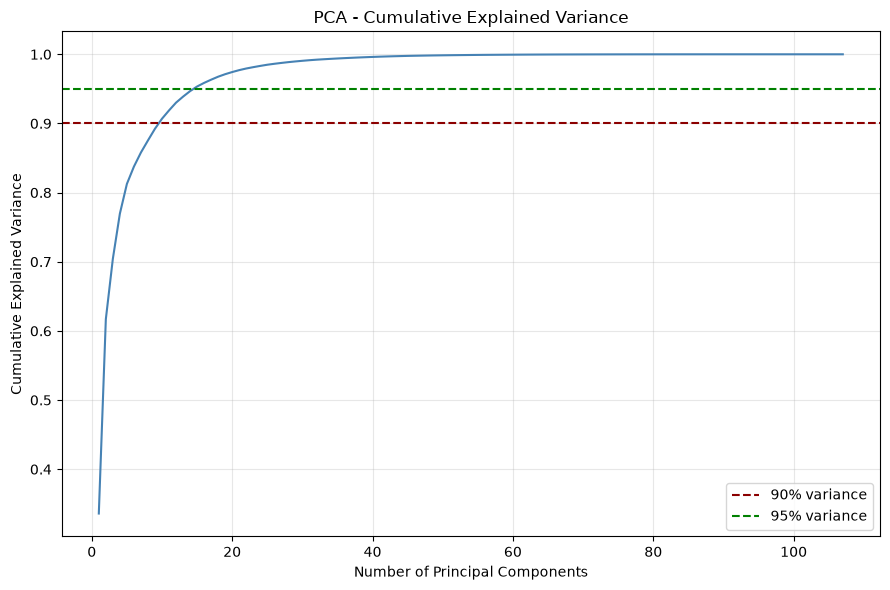

In [38]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize the radiomic features
scaler = StandardScaler()

scaled_training_features = scaler.fit_transform(
    training_features
)

# Apply PCA to all 107 features
pca = PCA()

pca.fit(scaled_training_features)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

# Find the number of components required
components_90 = np.searchsorted(cumulative_variance, 0.90) + 1
components_95 = np.searchsorted(cumulative_variance, 0.95) + 1

print("Original features:", training_features.shape[1])
print("Components for 90% variance:", components_90)
print("Components for 95% variance:", components_95)


# Visualize cumulative explained variance
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    color="steelblue"
)

ax.axhline(0.90, color="darkred", linestyle="--", label="90% variance")
ax.axhline(0.95, color="green", linestyle="--", label="95% variance")

ax.set_title("PCA - Cumulative Explained Variance")
ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

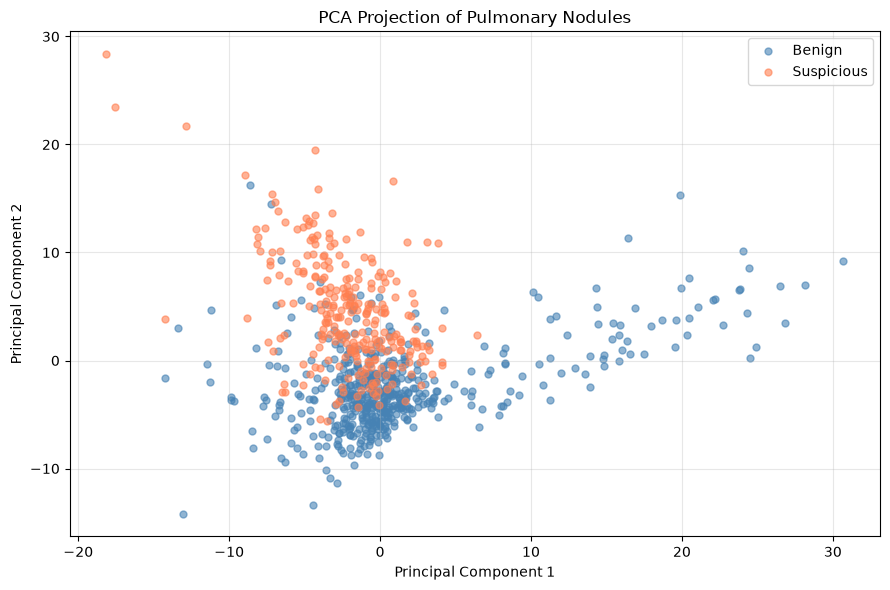

In [39]:
# Transform training data into principal components
principal_components = pca.transform(scaled_training_features)

# Get malignancy labels
malignancy_labels = training_labels.to_numpy()

# Create scatter plot
fig, ax = plt.subplots(figsize=(9, 6))

for malignancy_level in [0, 1]:

    selected_nodules = malignancy_labels == malignancy_level

    if malignancy_level == 0:
        label = "Benign"
        color = "steelblue"
    else:
        label = "Suspicious"
        color = "coral"

    ax.scatter(
        principal_components[selected_nodules, 0],
        principal_components[selected_nodules, 1],
        label=label,
        color=color,
        alpha=0.6,
        s=25
    )

# Configure plot
ax.set_title("PCA Projection of Pulmonary Nodules")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "pca_nodule_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Select the first 15 principal components
reduced_training_features = principal_components[:, :components_95]

# Create K-Means with two clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

# Identify clusters without using malignancy labels
cluster_labels = kmeans.fit_predict(reduced_training_features)

# Evaluate the clustering structure
silhouette = silhouette_score(
    reduced_training_features,
    cluster_labels
)

# Compare clusters with the original malignancy labels
adjusted_rand = adjusted_rand_score(
    training_labels,
    cluster_labels
)

print("Silhouette Score:", round(silhouette, 3))
print("Adjusted Rand Index:", round(adjusted_rand, 3))

print("\nNodules per cluster:")

for cluster_number in [0, 1]:
    cluster_count = (cluster_labels == cluster_number).sum()
    print(f"Cluster {cluster_number}: {cluster_count} nodules")

Silhouette Score: 0.302
Adjusted Rand Index: 0.388

Nodules per cluster:
Cluster 0: 207 nodules
Cluster 1: 586 nodules


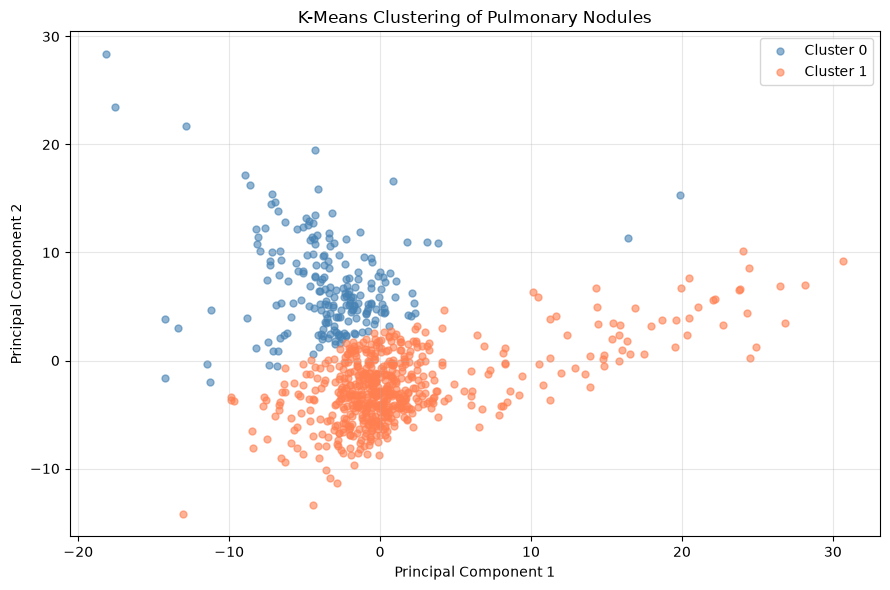

In [41]:
# Create scatter plot for K-Means clusters
fig, ax = plt.subplots(figsize=(9, 6))

cluster_colors = ["steelblue", "coral"]

for cluster_number in [0, 1]:

    selected_nodules = cluster_labels == cluster_number

    ax.scatter(
        principal_components[selected_nodules, 0],
        principal_components[selected_nodules, 1],
        color=cluster_colors[cluster_number],
        label=f"Cluster {cluster_number}",
        alpha=0.6,
        s=25
    )

# Configure plot
ax.set_title("K-Means Clustering of Pulmonary Nodules")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "kmeans_nodule_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
# Combine cluster assignments with malignancy labels
cluster_analysis = pd.DataFrame({
    "Cluster": cluster_labels,
    "Malignancy": training_labels.to_numpy()
})

# Count benign and suspicious nodules in each cluster
cluster_distribution = pd.crosstab(
    cluster_analysis["Cluster"],
    cluster_analysis["Malignancy"]
)

print("Nodules per cluster and malignancy:")
display(cluster_distribution)

# Calculate percentages within each cluster
cluster_percentages = pd.crosstab(
    cluster_analysis["Cluster"],
    cluster_analysis["Malignancy"],
    normalize="index"
) * 100

print("Malignancy distribution within each cluster (%):")
display(cluster_percentages.round(2))

Nodules per cluster and malignancy:


Malignancy,0,1
Cluster,,
0,39,168
1,480,106


Malignancy distribution within each cluster (%):


Malignancy,0,1
Cluster,,
0,18.84,81.16
1,81.91,18.09


,Clusters,Silhouette Score
0,2,0.302
1,3,0.364
2,4,0.222
3,5,0.240
4,6,0.245


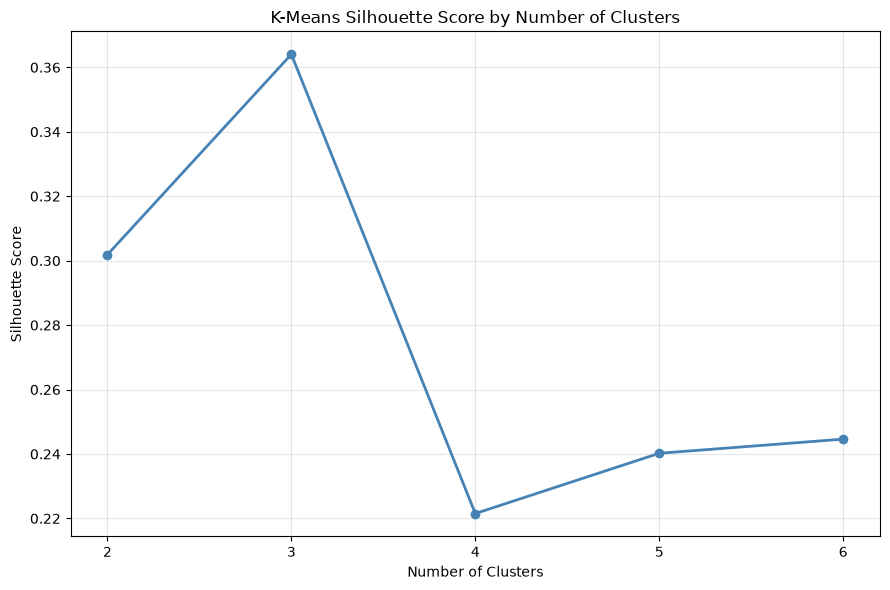

In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd

# Store clustering results
clustering_results = []

# Evaluate different numbers of clusters
for number_of_clusters in range(2, 7):

    # Create K-Means model
    kmeans_model = KMeans(
        n_clusters=number_of_clusters,
        random_state=42,
        n_init=20
    )

    # Assign each nodule to a cluster
    predicted_clusters = kmeans_model.fit_predict(
        reduced_training_features
    )

    # Calculate silhouette score
    silhouette = silhouette_score(
        reduced_training_features,
        predicted_clusters
    )

    # Store results
    clustering_results.append({
        "Clusters": number_of_clusters,
        "Silhouette Score": silhouette
    })

# Create results table
clustering_table = pd.DataFrame(clustering_results)

display(clustering_table.round(3))


# Visualize silhouette scores
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    clustering_table["Clusters"],
    clustering_table["Silhouette Score"],
    marker="o",
    color="steelblue",
    linewidth=2
)

ax.set_title("K-Means Silhouette Score by Number of Clusters")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(range(2, 7))
ax.grid(alpha=0.3)

plt.tight_layout()

# Save plot in results
fig.savefig(
    project_directory / "results" / "kmeans_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
# Create K-Means with three clusters
three_cluster_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

# Assign nodules to clusters
three_cluster_labels = three_cluster_model.fit_predict(
    reduced_training_features
)

# Compare clusters with malignancy labels
three_cluster_distribution = pd.crosstab(
    three_cluster_labels,
    training_labels.to_numpy(),
    normalize="index"
) * 100

print("Malignancy distribution per cluster (%):")
display(three_cluster_distribution.round(2))

# Evaluate agreement with malignancy labels
three_cluster_ari = adjusted_rand_score(
    training_labels,
    three_cluster_labels
)

print("Adjusted Rand Index:", round(three_cluster_ari, 3))

Malignancy distribution per cluster (%):


col_0,0,1
row_0,,
0,16.75,83.25
1,100.00,0.00
2,79.59,20.41


Adjusted Rand Index: 0.288


In [45]:
# Count nodules in each cluster
cluster_counts = pd.Series(three_cluster_labels).value_counts()

# Sort clusters by their identifier
cluster_counts = cluster_counts.sort_index()

print("Number of nodules per cluster:")
print(cluster_counts)

Number of nodules per cluster:
0    197
1     57
2    539
Name: count, dtype: int64
